In [1]:
from src.io_utils import load_data, coerce_numeric

df = coerce_numeric(load_data("data/library_loans.csv"))
df = df.dropna(subset=["loan_days"]).copy()
df = df[df["loan_days"] > 0].copy()

df["month"] = df["checkout_date"].dt.to_period("M").dt.to_timestamp()
df["week"] = df["checkout_date"].dt.to_period("W").dt.start_time

# df.info()

In [2]:
from src import metrics as M

print("Totalt antal lån:", M.total_loans(df))
print("Genomsnittlig lånetid (dagar:)", f"{M.avg_loan_days(df):.1f}")
print("Antel övertid (%):", f"{100 * M.overdue_rate(df):.1f}")

Totalt antal lån: 116
Genomsnittlig lånetid (dagar:) 21.3
Antel övertid (%): 47.6


In [3]:
by_genre = M.loans_by_genre(df)
by_branch = M.loans_by_branch(df)

by_genre
by_branch

,branch,loans
0,Öster,32
1,Väster,28
2,Norr,21
3,Centrum,20
4,Söder,13
5,NaN,3


In [4]:
ts_month = M.loans_over_time(df)
ts_week = M.loans_over_time(df, freq="W")

ts_month.head()
ts_week.head()

,checkout_date,loans
0,2025-01-05,2
1,2025-01-12,1
2,2025-01-19,2
3,2025-01-26,5
4,2025-02-02,6


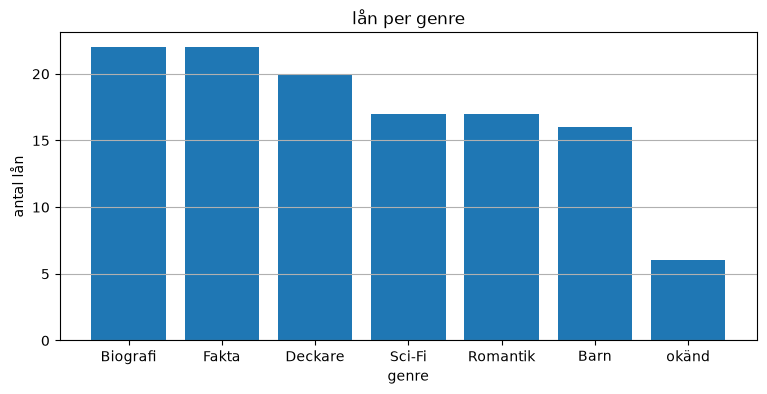

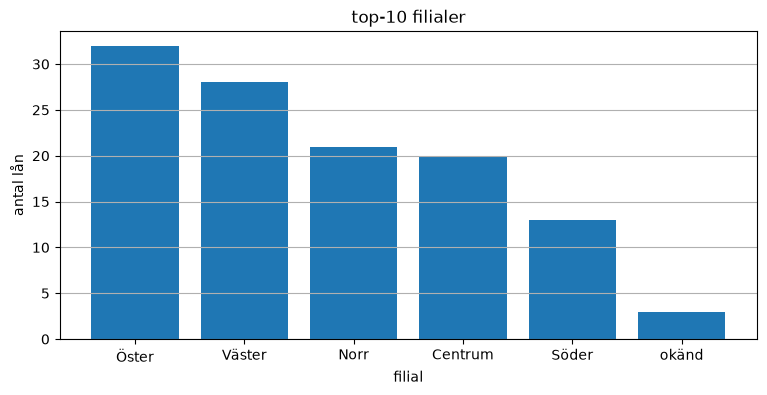

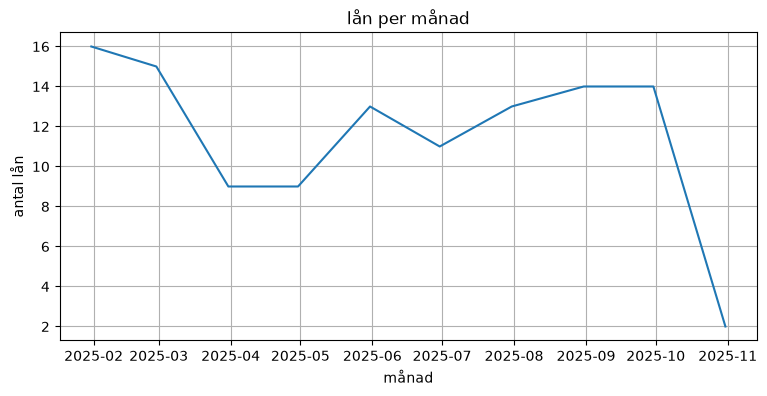

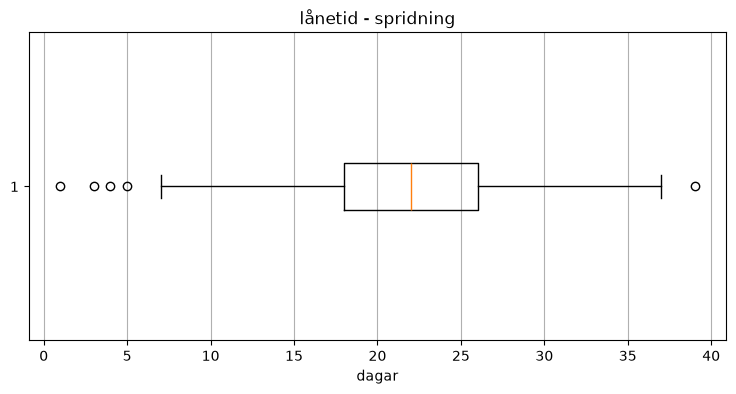

In [6]:
import matplotlib.pyplot as plt
from src import viz as V

fig, ax = plt.subplots(figsize=(9, 4))
V.bar(ax, by_genre["genre"], by_genre["loans"], "lån per genre", "genre", "antal lån")

fig, ax = plt.subplots(figsize=(9, 4))
top_10 = by_branch.head(10)
V.bar(ax, top_10["branch"], top_10["loans"], "top-10 filialer", "filial", "antal lån")

fig, ax = plt.subplots(figsize=(9, 4))
V.line(ax, ts_month["checkout_date"], ts_month["loans"], "lån per månad", "månad", "antal lån") 

fig, ax = plt.subplots(figsize=(9, 4))
V.box_h(ax, df["loan_days"], "lånetid - spridning", "dagar")